# 03 — Descriptive statistics

What is in the 1,126 cleaned instruction files, and what do the repos behind them look like? Descriptive only: no tests, no causal claims (those start in `06_correlations`).

**Input:** `data/interim/clean.parquet` (redacted text only). **Output:** `data/interim/desc_metrics.parquet` (per-file structure counts and tools mentioned, reused by `05_features`) and figures in `figures/`.

Definitions used below:
- **Length:** characters, words, and non-blank lines of the cleaned, resolved text.
- **Heading / section:** a markdown `#` heading outside code fences. *Sections* = level-2 headings.
- **Code block:** a fenced block (``` or ~~~). **Code share** = code lines / (code lines + prose lines), non-blank lines only. Prose lines include headings, bullets and tables.
- **Tools mentioned:** a keyword lexicon (below), matched anywhere in the file. A file counts once per tool. This is a first-pass lexicon; `05_features` formalizes `mentioned_tools`.
- **Groups:** `primary_file` = `CLAUDE.md` (repo has a `CLAUDE.md`) or `AGENTS.md` (repo has only an `AGENTS.md`). Medians are used throughout because lengths are heavily right-skewed.

In [1]:
import re
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
GROUP_COLORS = {"CLAUDE.md": "#4C72B0", "AGENTS.md": "#DD8452"}
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
pd.set_option("display.width", 200)

df = pd.read_parquet("data/interim/clean.parquet")
df["text"] = df["content_clean"]
print(df.shape, "| scraped", df.scraped_at.iloc[0])

(1126, 40) | scraped 2026-11-10


## 1. Corpus overview

In [2]:
n = len(df)
overview = pd.DataFrame({
    "repos": df.primary_file.value_counts(),
    "share": (df.primary_file.value_counts() / n).round(3),
})
print("resolved_from:"); print(df.resolved_from.value_counts().to_string())
print(f"\nredirects (CLAUDE.md pointing to AGENTS.md): {df.is_redirect.mean():.1%} | both files present: {df.has_both.mean():.1%}")
overview

resolved_from:
resolved_from
CLAUDE.md              641
AGENTS.md              462
CLAUDE.md+AGENTS.md     22
unresolved               1

redirects (CLAUDE.md pointing to AGENTS.md): 10.3% | both files present: 28.5%


,repos,share
primary_file,,
CLAUDE.md,757,0.672
AGENTS.md,369,0.328


## 2. Length

all files:
       n_chars_clean  n_words  n_lines
count         1126.0   1126.0   1126.0
mean          8363.0   1151.0    112.0
std          14188.0   2135.0    170.0
min            101.0      3.0      1.0
10%           1087.0    153.0     13.0
25%           2242.0    314.0     31.0
50%           4483.0    614.0     66.0
75%           9084.0   1241.0    127.0
90%          18017.0   2498.0    244.0
99%          65304.0   9621.0    798.0
max         228370.0  38096.0   2278.0

median by group:
              n_chars_clean  n_words  n_lines
primary_file                                 
AGENTS.md            3632.0    503.0     50.0
CLAUDE.md            5005.0    662.0     73.0


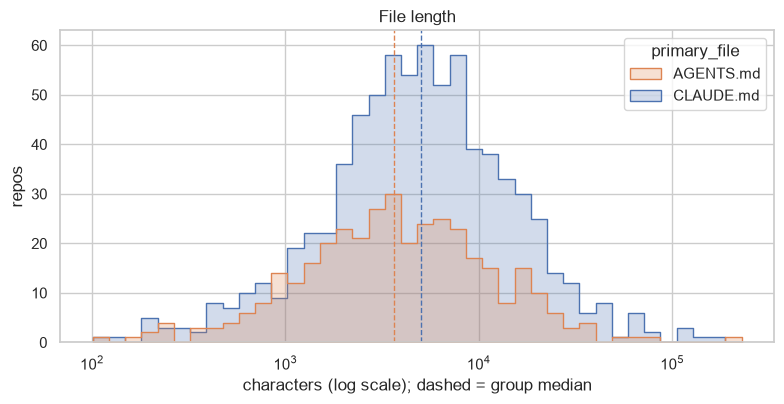

In [ ]:
df["n_words"] = df["text"].str.split().str.len()
df["n_lines"] = df["text"].map(lambda t: sum(1 for l in t.splitlines() if l.strip()))
cols = ["n_chars_clean", "n_words", "n_lines"]
print("all files:")
print(df[cols].describe(percentiles=[.1, .25, .5, .75, .9, .99]).round(0).to_string())
print("\nmedian by group:")
print(df.groupby("primary_file")[cols].median().round(0).to_string())

fig, ax = plt.subplots(figsize=(8, 4.2))
sns.histplot(data=df, x="n_chars_clean", hue="primary_file", log_scale=True, bins=40, element="step",
             palette=GROUP_COLORS, ax=ax)
for g, c in GROUP_COLORS.items():
    ax.axvline(df.loc[df.primary_file == g, "n_chars_clean"].median(), color=c, ls="--", lw=1)
ax.set(xlabel="characters (log scale); dashed = group median", ylabel="repos", title="File length")
fig.tight_layout(); fig.savefig(FIG / "length.png", dpi=150); plt.show()

## 3. The repos behind the files

language missing: 31 repos

top languages (repos, share):
            repos  share
language                
TypeScript    276  0.245
Python        253  0.225
JavaScript     99  0.088
Rust           65  0.058
Go             51  0.045
HTML           44  0.039
C#             26  0.023
Shell          25  0.022
Swift          24  0.021
C++            22  0.020
Kotlin         22  0.020
PHP            18  0.016

stars:
count    1126.0
mean       19.9
std       201.2
min         0.0
50%         0.0
75%         1.0
90%        11.0
99%       284.8
max      5330.0

star bins:
star_bin
0-10        1010
10-100        91
100-1000      18
1000-inf       7

has_tests: 38% | has_ci: 52%

repo age (years) and days since last push at scrape:
       age_years  days_since_push  repo_size_kb   forks
count     1126.0           1126.0        1126.0  1126.0
mean         1.1             98.0       34202.9     4.5
std          1.9            117.8      135999.6    50.6
min          0.0              0.0          

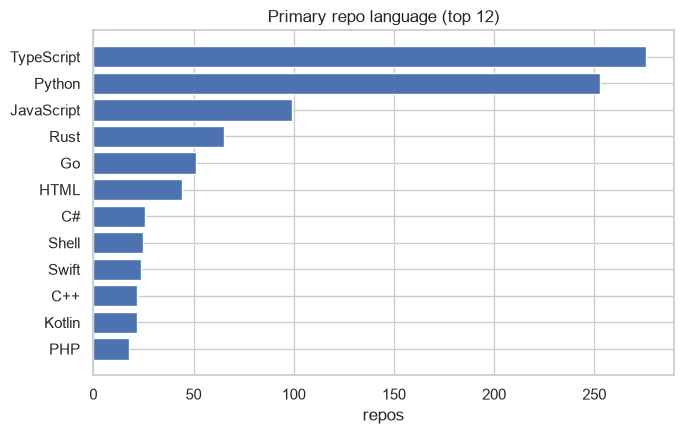

In [4]:
scraped = pd.Timestamp(df.scraped_at.iloc[0], tz="UTC")
df["age_years"] = ((scraped - pd.to_datetime(df.created_at, utc=True)).dt.days / 365.25).clip(lower=0)
df["days_since_push"] = (scraped - pd.to_datetime(df.last_push_at, utc=True)).dt.days.clip(lower=0)

print(f"language missing: {df.language.isna().sum()} repos")
lang = df.language.value_counts()
print("\ntop languages (repos, share):")
print(pd.DataFrame({"repos": lang.head(12), "share": (lang.head(12) / n).round(3)}).to_string())

print("\nstars:"); print(df.stars.describe(percentiles=[.5, .75, .9, .99]).round(1).to_string())
print("\nstar bins:"); print(df.star_bin.value_counts().sort_index().to_string())
print(f"\nhas_tests: {df.has_tests.mean():.0%} | has_ci: {df.has_ci.mean():.0%}")
print("\nrepo age (years) and days since last push at scrape:")
print(df[["age_years", "days_since_push", "repo_size_kb", "forks"]].describe(percentiles=[.25, .5, .75]).round(1).to_string())

top = lang.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top.index, top.values, color="#4C72B0")
ax.set(xlabel="repos", title="Primary repo language (top 12)")
fig.tight_layout(); fig.savefig(FIG / "languages.png", dpi=150); plt.show()

## 4. Structure: headings, sections, code blocks, code vs. prose
Parsed line by line so that `#` inside a fenced code block (shell comments, for example) is not counted as a heading.

all files:
       n_headings  n_sections  n_code_blocks  n_bullets  n_numbered  n_table_rows  code_share
count     1126.00     1126.00        1126.00    1126.00     1126.00       1126.00     1126.00
mean        11.48        6.18           2.31      30.56        5.21          6.06        0.13
std         10.73        4.39           4.66      39.24        9.31         17.18        0.16
min          0.00        0.00           0.00       0.00        0.00          0.00        0.00
25%          5.00        3.00           0.00       9.00        0.00          0.00        0.00
50%          8.00        6.00           1.00      19.00        0.00          0.00        0.06
75%         14.00        9.00           3.00      38.00        7.00          5.00        0.21
90%         24.00       12.00           6.00      69.00       15.00         18.00        0.36
max         87.00       28.00          69.00     413.00      137.00        206.00        0.99

no headings at all: 1.5% | no code blocks: 41.7%

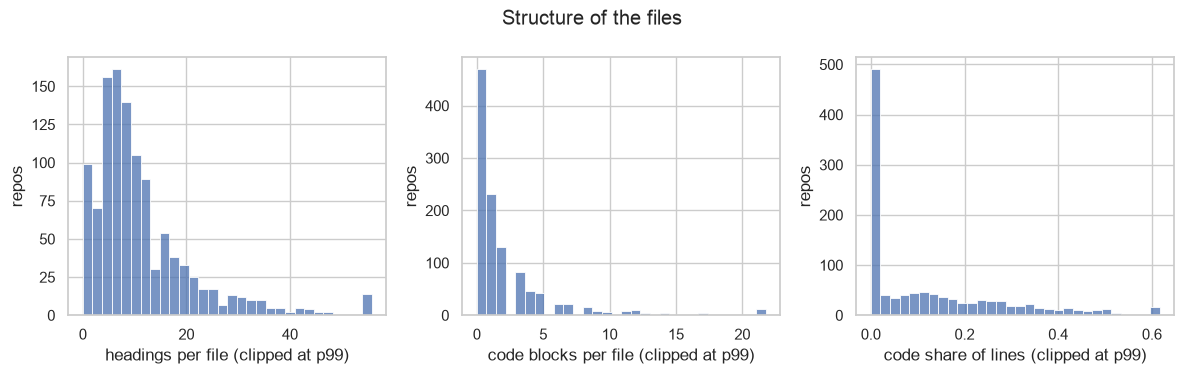

In [5]:
FENCE = re.compile(r"^\s*(```|~~~)")
HEAD = re.compile(r"^(#{1,6})\s+(.*?)\s*#*\s*$")
BULLET = re.compile(r"^\s*[-*+]\s+")
NUMBERED = re.compile(r"^\s*\d+[.)]\s+")

def parse(text):
    in_code, fence = False, None
    code_lines = prose_lines = blocks = bullets = numbered = table_rows = 0
    heads = []
    for line in text.splitlines():
        m = FENCE.match(line)
        if m:
            if not in_code:
                in_code, fence = True, m.group(1); blocks += 1
            elif m.group(1) == fence:
                in_code = False
            continue
        if not line.strip():
            continue
        if in_code:
            code_lines += 1; continue
        prose_lines += 1
        h = HEAD.match(line)
        if h:
            heads.append((len(h.group(1)), h.group(2)))
        elif BULLET.match(line):
            bullets += 1
        elif NUMBERED.match(line):
            numbered += 1
        s = line.strip()
        if s.startswith("|") and s.endswith("|"):
            table_rows += 1
    return {"n_headings": len(heads), "n_sections": sum(1 for l, _ in heads if l == 2),
            "n_code_blocks": blocks, "code_lines": code_lines, "prose_lines": prose_lines,
            "n_bullets": bullets, "n_numbered": numbered, "n_table_rows": table_rows, "_heads": heads}

parsed = df["text"].map(parse)
struct = pd.DataFrame(list(parsed), index=df.index)
df["heads"] = struct.pop("_heads")
for c in struct.columns:
    df[c] = struct[c]
df["code_share"] = df.code_lines / (df.code_lines + df.prose_lines).replace(0, np.nan)

scols = ["n_headings", "n_sections", "n_code_blocks", "n_bullets", "n_numbered", "n_table_rows", "code_share"]
print("all files:"); print(df[scols].describe(percentiles=[.25, .5, .75, .9]).round(2).to_string())
print(f"\nno headings at all: {(df.n_headings == 0).mean():.1%} | no code blocks: {(df.n_code_blocks == 0).mean():.1%} | contain a table: {(df.n_table_rows > 0).mean():.1%}")
print(f"mostly code (code share > 50%): {(df.code_share > 0.5).mean():.1%} | no code at all: {(df.code_share == 0).mean():.1%}")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, col, label in zip(axes, ["n_headings", "n_code_blocks", "code_share"],
                          ["headings per file", "code blocks per file", "code share of lines"]):
    x = df[col].dropna()
    sns.histplot(x=x.clip(upper=x.quantile(.99)), bins=30, color="#4C72B0", ax=ax)
    ax.set(xlabel=label + " (clipped at p99)", ylabel="repos")
fig.suptitle("Structure of the files"); fig.tight_layout(); fig.savefig(FIG / "structure.png", dpi=150); plt.show()

### Which sections do people write?

In [6]:
def norm_title(t):
    t = re.sub(r"[^a-z0-9&/+ -]", " ", t.lower())
    t = re.sub(r"^\s*\d+[.)]?\s*", "", t)
    return re.sub(r"\s+", " ", t).strip()

FILENAME_TITLES = {"claude md", "agents md", "claude", "agents"}      # a title that is just the file name says nothing
per_file_titles = df["heads"].map(lambda hs: {norm_title(t) for l, t in hs if l <= 3 and norm_title(t) and norm_title(t) not in FILENAME_TITLES})
title_counts = Counter(t for s in per_file_titles for t in s)
print("most common heading titles (h1-h3), share of files:")
print(pd.Series({t: c / n for t, c in title_counts.most_common(25)}).round(3).to_string())

THEMES = {
    "commands / build / setup":   r"command|\bbuild|setup|set up|install|getting started|development|\bdev\b|\brun\b|\brunning\b",
    "architecture / structure":   r"architecture|structure|overview|layout|\bdesign\b|organization|directory",
    "testing":                    r"\btest",
    "code style / conventions":   r"style|convention|guideline|standard|format|lint|naming|best practice",
    "rules / dos and don'ts":     r"\brules?\b|\bdo not\b|don.?t\b|\bnever\b|\balways\b|\bimportant\b|\bcritical\b|\bmust\b|\bavoid\b|restriction",
    "workflow / git / PRs":       r"workflow|\bgit\b|commit|pull request|\bprs?\b|branch|release|\bci\b",
    "tech stack / dependencies":  r"stack|technolog|dependenc|framework|librar",
}
theme_share = {k: per_file_titles.map(lambda s, rx=re.compile(v): any(rx.search(t) for t in s)).mean() for k, v in THEMES.items()}
print("\nfiles with at least one heading in each theme (keyword match on heading titles):")
pd.Series(theme_share).sort_values(ascending=False).round(3)

most common heading titles (h1-h3), share of files:
architecture                        0.211
project overview                    0.173
commands                            0.160
testing                             0.100
conventions                         0.081
project structure                   0.052
development commands                0.049
what this is                        0.042
stack                               0.036
code style                          0.034
tech stack                          0.033
rules                               0.033
dependencies                        0.029
documentation                       0.028
layout                              0.028
architecture overview               0.028
common commands                     0.027
configuration                       0.024
environment variables               0.024
this is not the next js you know    0.024
running tests                       0.023
overview                            0.023
development workflow    

commands / build / setup     0.604
architecture / structure     0.583
code style / conventions     0.433
rules / dos and don'ts       0.407
workflow / git / PRs         0.323
testing                      0.318
tech stack / dependencies    0.220
dtype: float64

## 5. Tools mentioned
A keyword lexicon, matched anywhere in the file (prose or code blocks). Patterns are deliberately conservative: for example `make` only counts as `make test`, `make build`, etc., or `Makefile`, so "make sure" is not a hit. Mentions of a tool do not mean it is required or used, only that the file names it.

files naming at least one tool: 86.9% | median distinct tools per file: 2 | mean: 2.8

share of files mentioning each tool (top 25):
git                 0.373
Claude Code         0.353
npm                 0.266
docker              0.139
MCP                 0.136
pytest              0.115
eslint              0.089
Codex               0.088
pip                 0.088
vitest              0.075
pnpm                0.073
make                0.068
github actions      0.067
cargo               0.067
ruff                0.066
uv                  0.065
gh cli              0.064
playwright          0.060
tsc                 0.056
go toolchain        0.048
Cursor              0.044
clippy / rustfmt    0.044
prettier            0.043
Copilot             0.040
Gemini              0.037

share of files mentioning at least one tool in each category:
package / build    0.603
AI tooling         0.480
version control    0.393
lint / format      0.244
testing            0.243
infra / CI         0.198


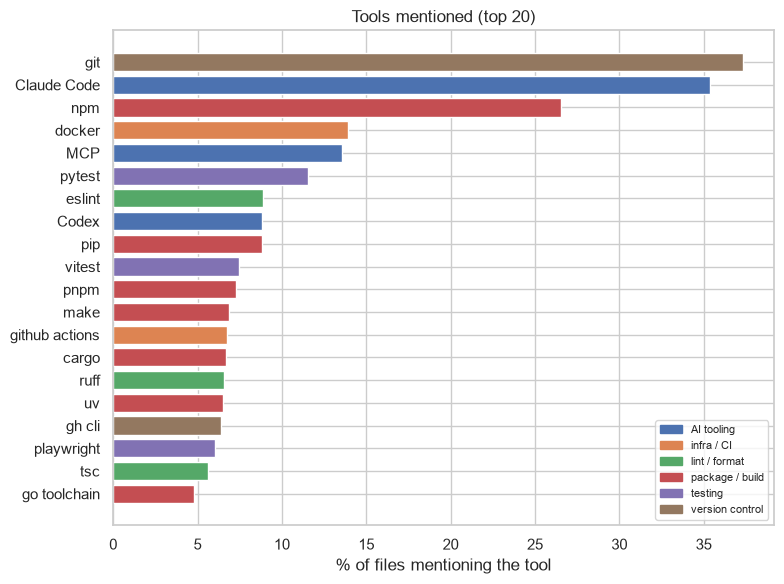

In [7]:
CI = re.I
TOOLS = [  # (name, category, pattern, flags)
    ("npm", "package / build", r"\bnpm\b", CI), ("pnpm", "package / build", r"\bpnpm\b", CI),
    ("yarn", "package / build", r"\byarn\b", CI), ("bun", "package / build", r"\bbun\b", CI),
    ("pip", "package / build", r"\bpip3?\b", CI), ("uv", "package / build", r"\buv (?:run|sync|pip|add|venv|tool|install)\b", CI),
    ("poetry", "package / build", r"\bpoetry\b", CI), ("cargo", "package / build", r"\bcargo\b", CI),
    ("go toolchain", "package / build", r"\bgo (?:test|build|run|mod|vet|fmt|install|generate)\b", CI),
    ("gradle", "package / build", r"\bgradlew?\b", CI), ("maven", "package / build", r"\bmvn\b|\bmaven\b", CI),
    ("make", "package / build", r"\bMakefile\b|\bmake (?:test|build|lint|install|run|all|check|dev|clean|fmt|format|docs|setup|ci)\b", CI),
    ("cmake", "package / build", r"\bcmake\b", CI), ("dotnet", "package / build", r"\bdotnet\b", CI),
    ("pytest", "testing", r"\bpytest\b", CI), ("jest", "testing", r"\bjest\b", CI),
    ("vitest", "testing", r"\bvitest\b", CI), ("mocha", "testing", r"\bmocha\b", CI),
    ("playwright", "testing", r"\bplaywright\b", CI), ("cypress", "testing", r"\bcypress\b", CI),
    ("junit", "testing", r"\bjunit\b", CI), ("rspec", "testing", r"\brspec\b", CI),
    ("eslint", "lint / format", r"\beslint\b", CI), ("prettier", "lint / format", r"\bprettier\b", CI),
    ("ruff", "lint / format", r"\bruff\b", CI), ("mypy", "lint / format", r"\bmypy\b", CI),
    ("black", "lint / format", r"`black\b|\bblack (?:\.|--|\S+\.py)|\bBlack\b(?= (?:formatter|format|code))", 0),
    ("flake8 / pylint", "lint / format", r"\bflake8\b|\bpylint\b", CI), ("clippy / rustfmt", "lint / format", r"\bclippy\b|\brustfmt\b", CI),
    ("biome", "lint / format", r"\bbiome\b", CI), ("tsc", "lint / format", r"\btsc\b", CI),
    ("docker", "infra / CI", r"\bdocker\b", CI), ("kubernetes", "infra / CI", r"\bkubernetes\b|\bkubectl\b", CI),
    ("terraform", "infra / CI", r"\bterraform\b", CI), ("github actions", "infra / CI", r"github actions", CI),
    ("git", "version control", r"\bgit\b", CI), ("gh cli", "version control", r"\bgh (?:pr|issue|run|api|repo)\b|`gh\b", CI),
    ("MCP", "AI tooling", r"\bMCP\b", 0), ("Cursor", "AI tooling", r"\bCursor\b", 0),
    ("Copilot", "AI tooling", r"\bCopilot\b", 0), ("Codex", "AI tooling", r"\bCodex\b", 0),
    ("Gemini", "AI tooling", r"\bGemini\b", 0), ("Claude Code", "AI tooling", r"\bClaude Code\b", 0),
]
RX = [(name, cat, re.compile(p, f)) for name, cat, p, f in TOOLS]
CATEGORY = {name: cat for name, cat, _ in RX}

df["tools_mentioned"] = df["text"].map(lambda t: [name for name, _, rx in RX if rx.search(t)])
df["n_tools"] = df["tools_mentioned"].map(len)

share = pd.Series(Counter(t for ts in df["tools_mentioned"] for t in ts)).div(n).sort_values(ascending=False)
print(f"files naming at least one tool: {(df.n_tools > 0).mean():.1%} | median distinct tools per file: {df.n_tools.median():.0f} | mean: {df.n_tools.mean():.1f}")
print("\nshare of files mentioning each tool (top 25):")
print(share.head(25).round(3).to_string())

cat_share = {c: df["tools_mentioned"].map(lambda ts, c=c: any(CATEGORY[t] == c for t in ts)).mean() for c in sorted(set(CATEGORY.values()))}
print("\nshare of files mentioning at least one tool in each category:")
print(pd.Series(cat_share).sort_values(ascending=False).round(3).to_string())

top = share.head(20).iloc[::-1]
cat_colors = dict(zip(sorted(set(CATEGORY.values())), sns.color_palette("deep", 6)))
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.values * 100, color=[cat_colors[CATEGORY[t]] for t in top.index])
ax.set(xlabel="% of files mentioning the tool", title="Tools mentioned (top 20)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in cat_colors.values()], labels=list(cat_colors), loc="lower right", fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "tools.png", dpi=150); plt.show()

### Boilerplate check
Some of the 'Claude Code' and heading counts above come from text that tools or templates generate. Counting files that contain a few well-known generated phrases shows how much of the corpus is default text rather than something the author chose to write.


In [8]:
BOILERPLATE = {
    "/init default: 'provides guidance to Claude Code'": r"provides guidance to Claude Code",
    "'claude.ai/code' link (from the /init default)": r"claude\.ai/code",
    "create-next-app AGENTS.md: 'not the Next.js you know'": r"not the next\.?js you know",
}
bp = pd.DataFrame({k: df["text"].str.contains(v, case=False, regex=True) for k, v in BOILERPLATE.items()})
print("share of files containing each generated phrase:")
print(bp.mean().round(3).to_string())
print("\nby group:"); print(bp.groupby(df.primary_file).mean().round(3).T.to_string())
df["has_init_boilerplate"] = bp.iloc[:, 0]
claude_no_boiler = df.loc[~df.has_init_boilerplate, "tools_mentioned"].map(lambda ts: "Claude Code" in ts).mean()
print(f"\n'Claude Code' mentioned in files WITHOUT the /init boilerplate: {claude_no_boiler:.1%}")

share of files containing each generated phrase:
/init default: 'provides guidance to Claude Code'        0.197
'claude.ai/code' link (from the /init default)           0.199
create-next-app AGENTS.md: 'not the Next.js you know'    0.024

by group:
primary_file                                           AGENTS.md  CLAUDE.md
/init default: 'provides guidance to Claude Code'          0.000      0.293
'claude.ai/code' link (from the /init default)             0.000      0.296
create-next-app AGENTS.md: 'not the Next.js you know'      0.016      0.028

'Claude Code' mentioned in files WITHOUT the /init boilerplate: 19.5%


## 6. CLAUDE.md repos vs. AGENTS.md-only repos (medians, no tests)

In [9]:
cmp_cols = ["n_chars_clean", "n_words", "n_headings", "n_sections", "n_code_blocks", "code_share", "n_bullets", "n_tools"]
comp = df.groupby("primary_file")[cmp_cols].median().T
comp["all"] = df[cmp_cols].median()
print("repos per group:", df.primary_file.value_counts().to_dict())
print("languages, share of each group in top 5 overall:")
top5 = df.language.value_counts().head(5).index
print(pd.crosstab(df.primary_file, df.language.where(df.language.isin(top5), "other"), normalize="index").round(2).to_string())
print(f"\nhas_tests by group: {df.groupby('primary_file').has_tests.mean().round(2).to_dict()}")
comp.round(2)

repos per group: {'CLAUDE.md': 757, 'AGENTS.md': 369}
languages, share of each group in top 5 overall:
language        Go  JavaScript  Python  Rust  TypeScript  other
primary_file                                                   
AGENTS.md     0.05        0.07    0.20  0.08        0.24   0.36
CLAUDE.md     0.04        0.10    0.24  0.05        0.25   0.33

has_tests by group: {'AGENTS.md': 0.37, 'CLAUDE.md': 0.39}


primary_file,AGENTS.md,CLAUDE.md,all
n_chars_clean,3632.0,5005.00,4483.00
n_words,503.0,662.00,614.00
n_headings,7.0,9.00,8.00
n_sections,5.0,6.00,6.00
n_code_blocks,0.0,1.00,1.00
code_share,0.0,0.09,0.06
n_bullets,18.0,20.00,19.00
n_tools,2.0,3.00,2.00


## 7. Checkpoint

In [10]:
keep = ["full_name", "primary_file", "resolved_from", "n_chars_clean", "n_words", "n_lines",
        "n_headings", "n_sections", "n_code_blocks", "code_lines", "prose_lines", "code_share",
        "n_bullets", "n_numbered", "n_table_rows", "n_tools", "tools_mentioned", "has_init_boilerplate", "age_years", "days_since_push"]
df[keep].to_parquet("data/interim/desc_metrics.parquet", index=False)
print("saved data/interim/desc_metrics.parquet", df[keep].shape)

saved data/interim/desc_metrics.parquet (1126, 20)
